/tmp/ipykernel_574/1347218789.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pil_gray = Image.fromarray(arr, mode="L")


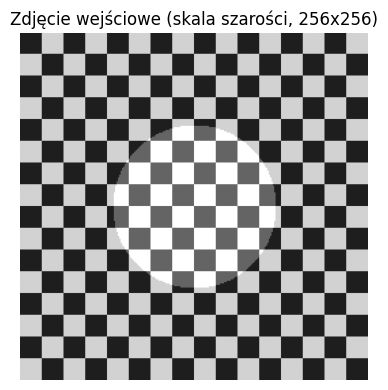

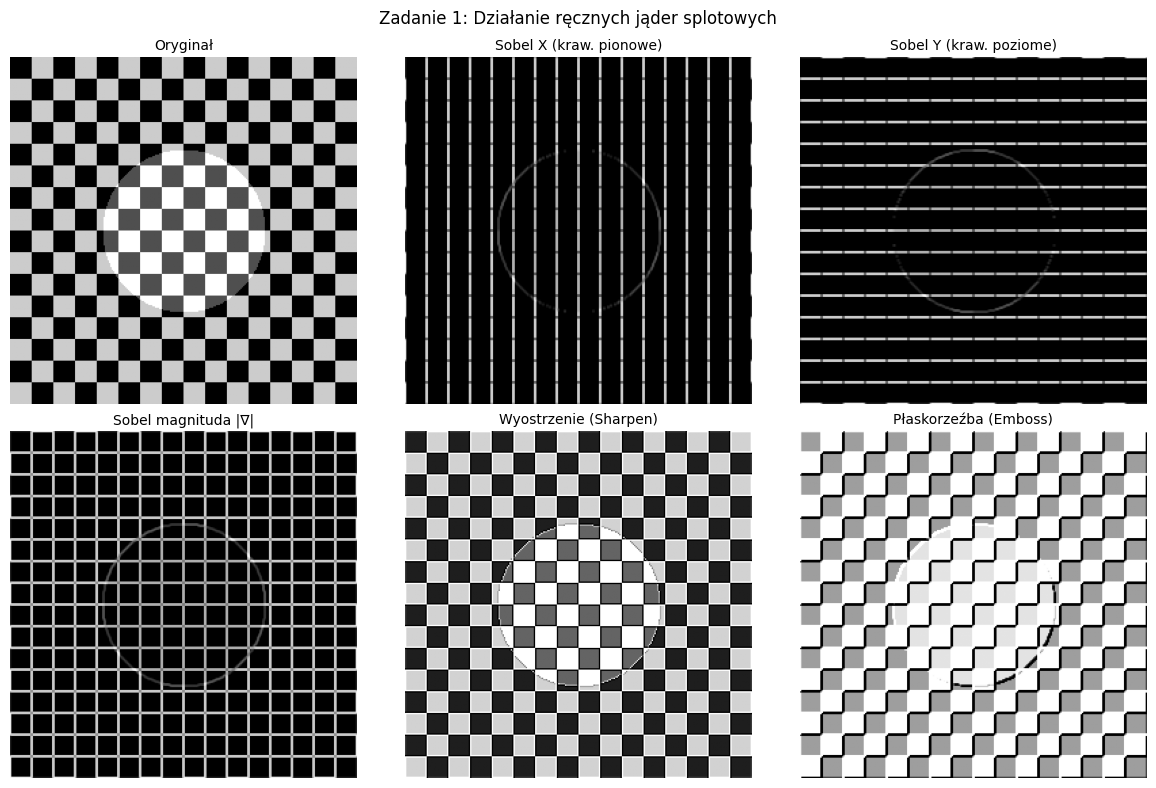


--- ZADANIE 2: Weryfikacja wymiarów dla wejścia 256x256 ---
  k |   s |   p |   d | Wzór (H_out) |  nn.Conv2d | Zgodność
----------------------------------------------------------
  3 |   1 |   1 |   1 |          256 |        256 |      TAK
  3 |   2 |   1 |   1 |          128 |        128 |      TAK
  5 |   1 |   0 |   1 |          252 |        252 |      TAK
  3 |   1 |   2 |   2 |          256 |        256 |      TAK
  7 |   2 |   3 |   1 |          128 |        128 |      TAK
  5 |   3 |   2 |   2 |           84 |         84 |      TAK


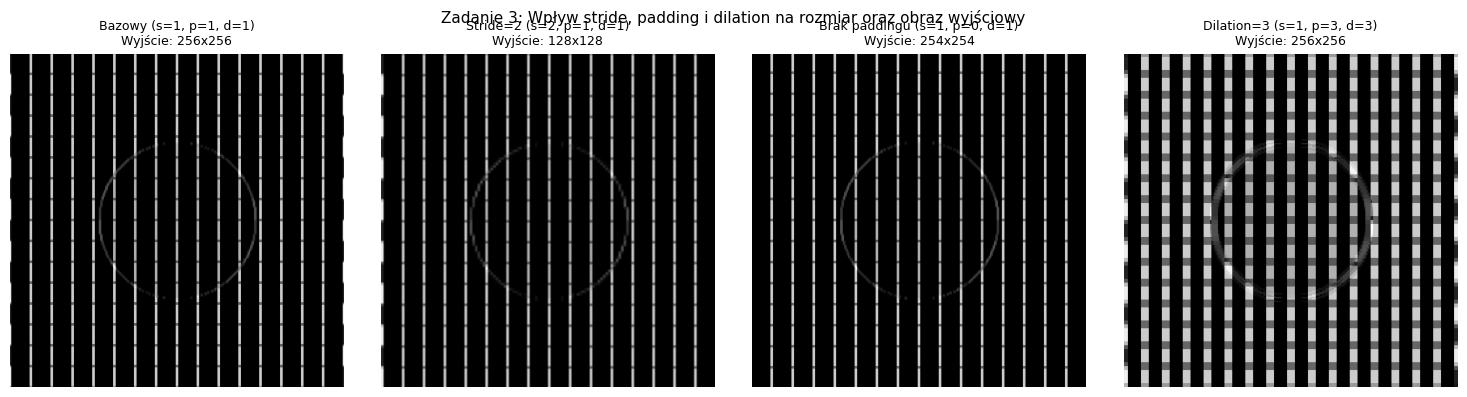

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s]


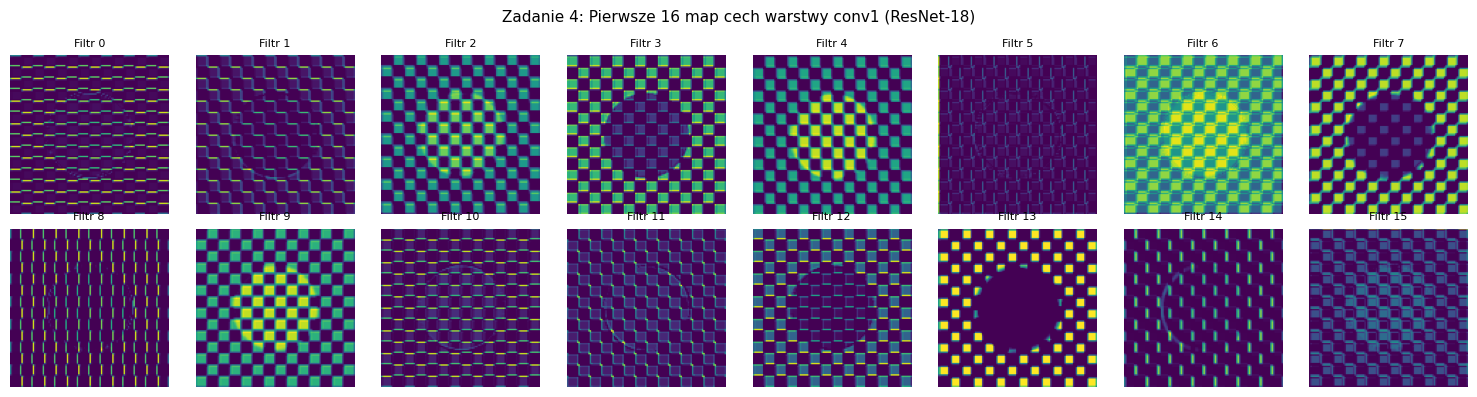

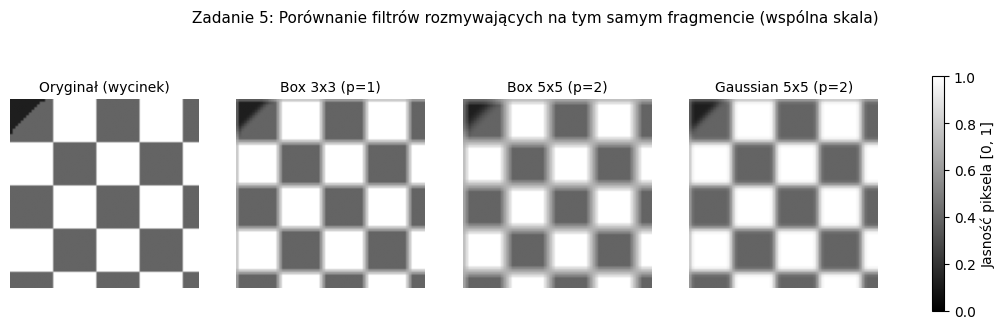

In [1]:
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

url = "https://upload.wikimedia.org/wikipedia/commons/thumb/4/47/PNG_transparency_demonstration_1.png/560px-PNG_transparency_demonstration_1.png"
try:
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as resp, open("wlasne_zdjecie.png", "wb") as f:
        f.write(resp.read())
    pil_gray = Image.open("wlasne_zdjecie.png").convert("L").resize((256, 256))
except Exception:

    from torchvision.datasets import FakeData
    yy, xx = np.mgrid[0:256, 0:256]
    chess = (((xx // 16) + (yy // 16)) % 2) * 180 + 30
    circle = ((xx - 128)**2 + (yy - 128)**2 < 60**2) * 70
    arr = np.clip(chess + circle, 0, 255).astype(np.uint8)
    pil_gray = Image.fromarray(arr, mode="L")


gray = torch.from_numpy(np.array(pil_gray)).float().unsqueeze(0).unsqueeze(0) / 255.0

plt.figure(figsize=(4, 4))
plt.imshow(gray[0, 0], cmap="gray", vmin=0, vmax=1)
plt.title("Zdjęcie wejściowe (skala szarości, 256x256)")
plt.axis("off")
plt.tight_layout()
plt.show()


def make_kernel(weights):
    t = torch.tensor(weights, dtype=torch.float32)
    return t.view(1, 1, t.shape[0], t.shape[1])

sobel_x = make_kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = make_kernel([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
sharpen = make_kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
emboss  = make_kernel([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]])

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
sobel_mag = torch.sqrt(gx**2 + gy**2)
out_sharpen = F.conv2d(gray, sharpen, padding=1).clamp(0, 1)
out_emboss = (F.conv2d(gray, emboss, padding=1) + 0.5).clamp(0, 1)

kernels_vis = [
    ("Oryginał", gray),
    ("Sobel X (kraw. pionowe)", gx.abs()),
    ("Sobel Y (kraw. poziome)", gy.abs()),
    ("Sobel magnituda |∇|", sobel_mag),
    ("Wyostrzenie (Sharpen)", out_sharpen),
    ("Płaskorzeźba (Emboss)", out_emboss),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (title, img_t) in zip(axes.flat, kernels_vis):
    ax.imshow(img_t[0, 0].detach(), cmap="gray")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.suptitle("Zadanie 1: Działanie ręcznych jąder splotowych", fontsize=12)
plt.tight_layout()
plt.show()


def calc_out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2 * p - d * (k - 1) - 1) // s + 1

IN_SIZE = gray.shape[-1]  # 256
configs = [
    {"k": 3, "s": 1, "p": 1, "d": 1},
    {"k": 3, "s": 2, "p": 1, "d": 1},
    {"k": 5, "s": 1, "p": 0, "d": 1},
    {"k": 3, "s": 1, "p": 2, "d": 2},
    {"k": 7, "s": 2, "p": 3, "d": 1},
    {"k": 5, "s": 3, "p": 2, "d": 2},
]

print(f"\n--- ZADANIE 2: Weryfikacja wymiarów dla wejścia {IN_SIZE}x{IN_SIZE} ---")
print(f"{'k':>3} | {'s':>3} | {'p':>3} | {'d':>3} | {'Wzór (H_out)':>12} | {'nn.Conv2d':>10} | {'Zgodność':>8}")
print("-" * 58)
for cfg in configs:
    conv = nn.Conv2d(1, 4, kernel_size=cfg["k"], stride=cfg["s"], padding=cfg["p"], dilation=cfg["d"])
    out_tensor = conv(gray)
    actual_h = out_tensor.shape[-2]
    formula_h = calc_out_dim(IN_SIZE, **cfg)
    match = "TAK" if actual_h == formula_h else "NIE"
    print(f"{cfg['k']:>3} | {cfg['s']:>3} | {cfg['p']:>3} | {cfg['d']:>3} | {formula_h:>12} | {actual_h:>10} | {match:>8}")


param_settings = [
    ("Bazowy (s=1, p=1, d=1)", dict(stride=1, padding=1, dilation=1)),
    ("Stride=2 (s=2, p=1, d=1)", dict(stride=2, padding=1, dilation=1)),
    ("Brak paddingu (s=1, p=0, d=1)", dict(stride=1, padding=0, dilation=1)),
    ("Dilation=3 (s=1, p=3, d=3)", dict(stride=1, padding=3, dilation=3)),
]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (label, params) in zip(axes, param_settings):
    out = F.conv2d(gray, sobel_mag_k := sobel_x, **params)
    h, w = out.shape[-2:]
    ax.imshow(out[0, 0].abs().detach(), cmap="gray")
    ax.set_title(f"{label}\nWyjście: {h}x{w}", fontsize=9)
    ax.axis("off")
plt.suptitle("Zadanie 3: Wpływ stride, padding i dilation na rozmiar oraz obraz wyjściowy", fontsize=11)
plt.tight_layout()
plt.show()


weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()


gray_3ch = gray.repeat(1, 3, 1, 1)  # [1, 3, 256, 256]
preprocess = weights.transforms()
input_resnet = preprocess(gray_3ch).to(device)

with torch.no_grad():

    feature_maps = torch.relu(model.conv1(input_resnet))[0].cpu()

fig, axes = plt.subplots(2, 8, figsize=(15, 4))
for idx, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[idx], cmap="viridis")
    ax.set_title(f"Filtr {idx}", fontsize=8)
    ax.axis("off")
plt.suptitle("Zadanie 4: Pierwsze 16 map cech warstwy conv1 (ResNet-18)", fontsize=11)
plt.tight_layout()
plt.show()


box_3 = torch.ones((1, 1, 3, 3), dtype=torch.float32) / 9.0
box_5 = torch.ones((1, 1, 5, 5), dtype=torch.float32) / 25.0

g_1d = torch.tensor([1., 4., 6., 4., 1.])
gauss_5 = torch.outer(g_1d, g_1d)
gauss_5 = (gauss_5 / gauss_5.sum()).view(1, 1, 5, 5)


out_box3 = F.conv2d(gray, box_3, stride=1, padding=1, dilation=1)
out_box5 = F.conv2d(gray, box_5, stride=1, padding=2, dilation=1)
out_gauss5 = F.conv2d(gray, gauss_5, stride=1, padding=2, dilation=1)


y1, y2, x1, x2 = 80, 150, 80, 150
crops = [
    ("Oryginał (wycinek)", gray[0, 0, y1:y2, x1:x2]),
    ("Box 3x3 (p=1)", out_box3[0, 0, y1:y2, x1:x2]),
    ("Box 5x5 (p=2)", out_box5[0, 0, y1:y2, x1:x2]),
    ("Gaussian 5x5 (p=2)", out_gauss5[0, 0, y1:y2, x1:x2]),
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (title, crop) in zip(axes, crops):

    im = ax.imshow(crop.detach(), cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="Jasność piksela [0, 1]")
plt.suptitle("Zadanie 5: Porównanie filtrów rozmywających na tym samym fragmencie (wspólna skala)", fontsize=11)
plt.show()